# SupeRR Selector: Pressure Index Mathematical Modelling

In cricket analytics, traditional box-score metrics fail to capture the true context of performance. A batter scoring 35 off 25 balls when needing 15 off 30 with 8 wickets in hand is executing a routine chase, whereas scoring the same 35 off 25 when needing 60 off 36 with 3 wickets in hand represents a match-winning clutch performance. Similarly, bowling a dot ball in the 3rd over with 10 wickets in hand carries vastly different stakes than bowling a dot ball in the 20th over with 4 runs to defend.

In this notebook, I develop a cricket-aware, delivery-level Pressure Index ($PI \in [0.0, 10.0]$). Rather than arbitrarily labelling deliveries as high pressure based on dramatic outcomes, our framework evaluates match tension strictly before each ball is bowled by comparing the scoring demand against historical empirical resource capacity across both standard chases and first-innings situations.


## 1. Setting Up the Pipeline and Importing Modular Functions

To ensure reproducibility, maintainability, and clean code architecture, all core mathematical formulas and calibration routines are housed in `src/pressure_calibration.py`, `src/pressure_model.py`, and `src/data_validator.py`. This notebook executes the analytical workflow, visualizes key dynamics, and validates the pressure framework step by step.

Here I import Pandas, NumPy, visualization libraries, and our custom engineering functions.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Ensure project root is in system path for modular imports
root_path = os.path.abspath("..") if os.path.exists("../src") else os.path.abspath(".")
if root_path not in sys.path:
    sys.path.insert(0, root_path)

from src.pressure_calibration import (
    calibrate_resource_parameters,
    get_empirical_scoring_grid,
    parametric_resource_function,
    assign_pressure_category
)
from src.pressure_model import (
    calculate_delivery_pressure,
    calculate_chasing_pressure,
    calculate_first_innings_pressure,
    calculate_bowling_pressure,
    calculate_super_over_pressure
)
from src.data_validator import validate_pressure_model

# Set clean aesthetic styling for cricket analytics visualizations
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
print("Engineering modules and plotting environment successfully initialized.")


Engineering modules and plotting environment successfully initialized.


## 2. Ingesting Module 2 Match-State Data and Format Metadata

Before constructing the pressure model, we load the reconstructed delivery-level match-state dataset from Module 2 (`data/processed/ball_by_ball_state.parquet`) along with tournament format metadata from `competitions.csv`.

In Module 1 and Module 2, we established that our dataset spans two distinct competitive formats: T20 Internationals (482 matches) and Franchise T20 leagues (401 matches, led by IPL 2022-2026). In modern T20 cricket, scoring conditions differ substantially between international bilateral series and the IPL due to boundary dimensions, pitch preparation, and tactical innovations like the Impact Player rule. Merging format metadata ensures our baseline models remain format-aware.


In [2]:
# Load delivery-level state dataset
df_state = pd.read_parquet("../data/processed/ball_by_ball_state.parquet" if os.path.exists("../data/processed") else "data/processed/ball_by_ball_state.parquet")
matches = pd.read_csv("../Data Pack/matches.csv" if os.path.exists("../Data Pack") else "Data Pack/matches.csv")
comps = pd.read_csv("../Data Pack/competitions.csv" if os.path.exists("../Data Pack") else "Data Pack/competitions.csv")

# Merge competition format
mc = matches.merge(comps[["comp_id", "match_format", "comp_name"]], on="comp_id")
df_state = df_state.merge(mc[["match_id", "match_format"]], on="match_id", how="left")
df_state["match_format"] = df_state["match_format"].fillna("T20")

print(f"Loaded delivery dataset: {df_state.shape[0]:,} rows, {df_state.shape[1]} columns")
print(f"Format distribution:\n{df_state['match_format'].value_counts()}")


Loaded delivery dataset: 200,999 rows, 59 columns
Format distribution:
match_format
T20I    106327
T20      94672
Name: count, dtype: int64


## 3. Understanding Pre-Delivery Match-State Variables

The foundation of our pressure framework rests entirely on pre-delivery match context. To ensure absolute freedom from lookahead and outcome leakage, no feature calculated after the ball is bowled (such as runs scored off the bat, extras conceded, or wickets taken on this ball) is permitted to influence the pre-delivery pressure score.

The primary pre-delivery variables include:
* `balls_remaining_before`: Legal deliveries remaining in the innings (standard max 120).
* `wickets_in_hand_before`: Batting survival capital ($10 - \text{wickets\_lost}$).
* `cumulative_runs_before`: Runs scored on the board prior to this delivery.
* `required_run_rate_before`: Target scoring demand per over in chases (Innings 2 & 4).
* `runs_needed_before`: Absolute runs required to win the match.
* `over_phase`: Structural stage of the game (`Powerplay`, `Middle`, `Death`, `Super Over`).


In [3]:
# Inspect pre-delivery variables across a sample chase sequence
sample_cols = [
    "match_id", "innings", "overid", "over_ball_num", "cumulative_runs_before",
    "wickets_in_hand_before", "balls_remaining_before", "runs_needed_before",
    "required_run_rate_before", "over_phase"
]
print("Sample pre-delivery state variables:")
display(df_state[df_state["innings"] == 2][sample_cols].head(5))


Sample pre-delivery state variables:
     match_id  innings  overid  over_ball_num  cumulative_runs_before  wickets_in_hand_before  balls_remaining_before  runs_needed_before  required_run_rate_before over_phase
121     13511        2       1              1                       0                      10                     120               104.0                  5.200000  Powerplay
122     13511        2       1              2                       0                      10                     119               104.0                  5.243697  Powerplay
123     13511        2       1              3                       4                      10                     118               100.0                  5.084746  Powerplay
124     13511        2       1              4                       4                      10                     117               100.0                  5.128205  Powerplay
125     13511        2       1              5                       4                   

## 4. Empirical Scoring Baselines: Duckworth-Lewis Style Resource Modeling

To evaluate whether a chase or first-innings total is under pressure, we need an objective, data-driven answer to a fundamental cricket question: **How many runs does a T20 team typically score from this exact match state ($B_{\text{rem}}, W_{\text{hand}}$)?**

In cricket analytics, Frank Duckworth and Tony Lewis demonstrated that team scoring capacity is non-linear: losing wickets rapidly degrades scoring acceleration because lower-order batters have lower boundary percentages and face the risk of being bowled out.

We model expected remaining runs using a parametric power-resource function:
$$\mu_{\text{runs}}(B, W) = a \cdot \left(\frac{B}{120}\right)^\beta \cdot \left(\frac{W}{10}\right)^\gamma$$
where:
* $a$ represents the format baseline par score with 120 balls and 10 wickets in hand.
* $\beta$ captures the sub-linear elasticity of remaining balls (~0.69 - 0.70).
* $\gamma$ captures the power-law penalty of wicket depletion (~0.48 - 0.61).

To rigorously prevent data leakage, we calibrate $(a, \beta, \gamma)$ using 5-fold match-level cross-validation (`GroupKFold`), ensuring no match's deliveries are evaluated against a baseline influenced by its own final score.


In [4]:
# Calibrate format-specific resource parameters with GroupKFold out-of-fold validation
calibrated_params = calibrate_resource_parameters(df_state, n_splits=5)

for fmt, params in calibrated_params.items():
    print(f"=== Calibrated Resource Parameters for [{fmt}] ===")
    print(f"  Format Par Score (a): {params['par_total']:.1f} runs")
    print(f"  Balls Exponent (beta): {params['beta']:.3f}")
    print(f"  Wickets Exponent (gamma): {params['gamma']:.3f}")
    print(f"  Out-of-Fold R^2: {params['r2_out_of_fold']:.3f}\n")


=== Calibrated Resource Parameters for [T20] ===
  Format Par Score (a): 184.9 runs
  Balls Exponent (beta): 0.689
  Wickets Exponent (gamma): 0.608
  Out-of-Fold R^2: 0.833

=== Calibrated Resource Parameters for [T20I] ===
  Format Par Score (a): 171.7 runs
  Balls Exponent (beta): 0.704
  Wickets Exponent (gamma): 0.476
  Out-of-Fold R^2: 0.784



## 5. Visualizing the Empirical Resource Matrix vs Fitted Curves

To verify that our smooth parametric function accurately reflects real-world cricket behavior, we compare its predictions against the raw empirical scoring grid aggregated from historical 1st innings data.

The chart below compares expected remaining runs across different wicket levels as overs tick down.


<string>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


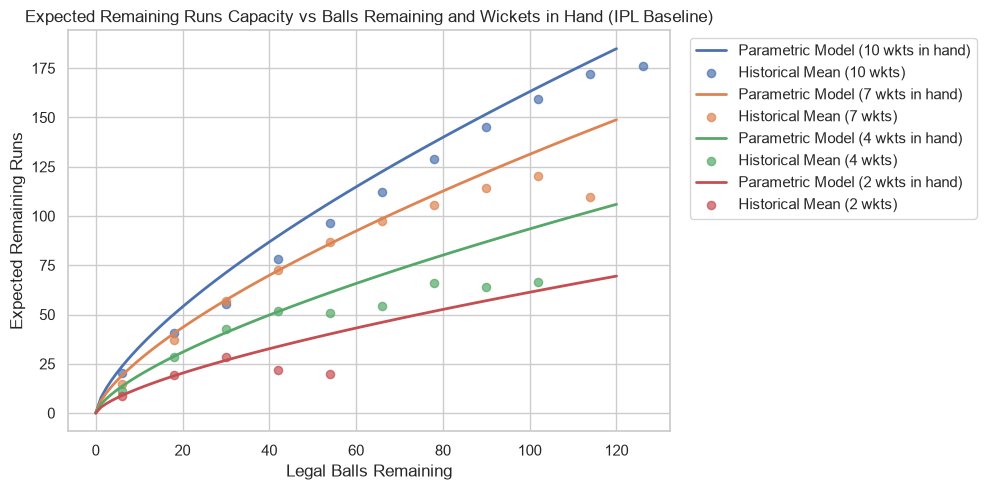

In [5]:
# Generate empirical grid and parametric curves for visual comparison
grid = get_empirical_scoring_grid(df_state, balls_bin_size=12)

# Plotting remaining runs progression
fig, ax = plt.subplots(figsize=(10, 5))
balls = np.linspace(0, 120, 100)

for w in [10, 7, 4, 2]:
    t20_curve = parametric_resource_function(balls, np.full_like(balls, w), 184.9, 0.688, 0.608)
    ax.plot(balls, t20_curve, label=f"Parametric Model ({w} wkts in hand)", linewidth=2)
    
    # Plot empirical points where available
    if w in grid.columns.levels[1]:
        emp_pts = grid["mean"][w].dropna()
        ax.scatter(emp_pts.index + 6, emp_pts.values, s=35, alpha=0.7, label=f"Historical Mean ({w} wkts)")

ax.set_xlabel("Legal Balls Remaining")
ax.set_ylabel("Expected Remaining Runs")
ax.set_title("Expected Remaining Runs Capacity vs Balls Remaining and Wickets in Hand (IPL Baseline)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 6. Chasing Pressure Framework (Innings 2 & Super Over Innings 4)

In a chase, batting pressure is not simply the Required Run Rate. Needing 12 RPO with 8 wickets in hand in the 14th over is an achievable acceleration challenge, whereas needing 12 RPO with 2 wickets in hand in the 18th over is an existential crisis where any single delivery can end the match.

Our chasing framework evaluates four distinct pressure drivers:
1. **Demand-to-Capacity Ratio ($D$):**
   $$D = \frac{\text{runs\_needed}}{\max(E_{\text{rem}}(B, W), 1.0)}$$
   When $D = 1.0$, the batting team needs exactly what an average team scores from that position (50/50 balance). When $D > 1.4$, they face severe resource deficits.
2. **Required Run Rate Intensity ($\text{RRR}_{\text{norm}}$):**
   $$\text{RRR}_{\text{norm}} = \text{clip}\left(\frac{\text{RRR}}{16.0}, 0.0, 1.25\right)$$
   Reflects the boundary demand per over.
3. **Wicket Fragility ($W_{\text{dep}}$):**
   $$W_{\text{dep}} = \frac{10 - W_{\text{hand}}}{9}$$
   Captures batting depth depletion.
4. **Late-Overs Urgency ($B_{\text{elap}}$):**
   $$B_{\text{elap}} = 1 - \frac{B_{\text{rem}}}{120}$$
   Amplifies pressure in the death overs where dot balls cannot be amortized.

$$PI_{\text{chase}} = 4.5 \cdot \text{sigmoid}(2.2 \cdot (D - 1.0)) + 3.2 \cdot \text{RRR}_{\text{norm}} + 2.3 \cdot (W_{\text{dep}} \cdot B_{\text{elap}})$$

If the target has already been achieved before the ball is bowled ($\text{runs\_needed} \le 0$), pressure is strictly 0.0.


<string>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


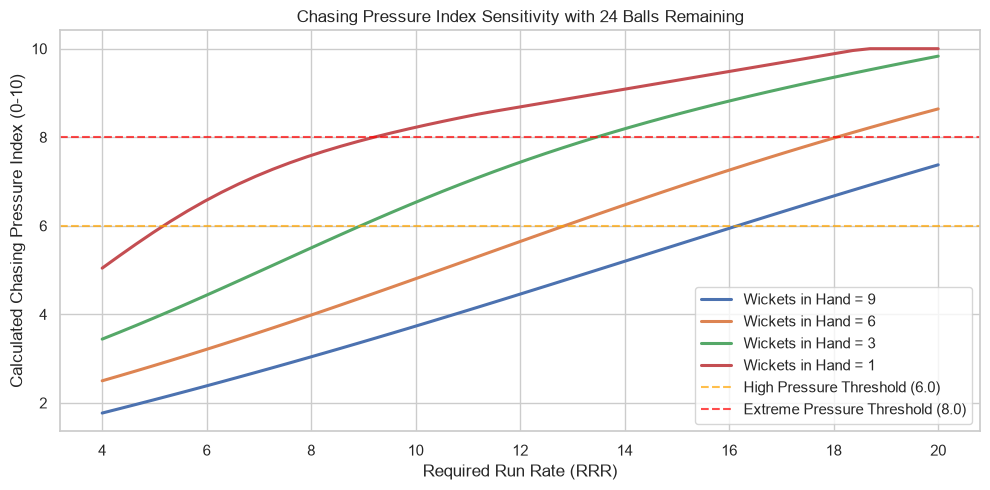

In [6]:
# Inspect chasing pressure sensitivity across synthetic combinations
rrr_vals = np.linspace(4, 20, 50)
wkt_levels = [9, 6, 3, 1]

fig, ax = plt.subplots(figsize=(10, 5))
for w in wkt_levels:
    # Synthesize state at 24 balls remaining (4 overs left)
    b_rem = np.full_like(rrr_vals, 24)
    runs_req = (rrr_vals / 6.0) * b_rem
    e_rem = parametric_resource_function(b_rem, np.full_like(rrr_vals, w), 184.9, 0.688, 0.608)
    p_scores = calculate_chasing_pressure(runs_req, b_rem, np.full_like(rrr_vals, w), rrr_vals, e_rem)
    ax.plot(rrr_vals, p_scores, label=f"Wickets in Hand = {w}", linewidth=2.2)

ax.set_xlabel("Required Run Rate (RRR)")
ax.set_ylabel("Calculated Chasing Pressure Index (0-10)")
ax.set_title("Chasing Pressure Index Sensitivity with 24 Balls Remaining")
ax.axhline(6.0, color="orange", linestyle="--", alpha=0.7, label="High Pressure Threshold (6.0)")
ax.axhline(8.0, color="red", linestyle="--", alpha=0.7, label="Extreme Pressure Threshold (8.0)")
ax.legend()
plt.tight_layout()
plt.show()


## 7. First-Innings Batting Pressure Framework (Innings 1)

In the first innings, there is no fixed target to chase. Inventing an arbitrary Required Run Rate would be statistically invalid. Instead, first-innings pressure is driven by three factual forces:

1. **Par Deficit ($\Delta \text{Par}$):**
   $$\text{Projected Score} = \text{cumulative\_runs\_before} + E_{\text{rem}}(B, W)$$
   $$\Delta \text{Par} = \text{Par Total} - \text{Projected Score}$$
   If early wickets drag projected total 30 runs below par (e.g. 150 vs par 183), the team faces high pressure to arrest the slide.
2. **Collapse Severity ($C_{\text{sev}}$):**
   $$C_{\text{sev}} = \left(\frac{10 - W_{\text{hand}}}{9}\right) \cdot \left(\frac{B_{\text{rem}}}{120}\right)^{0.75}$$
   Losing 4 wickets in the first 36 balls represents a catastrophic collapse ($C_{\text{sev}} \gg 0$), whereas losing 4 wickets with 12 balls remaining is standard death-overs hitting.
3. **Death-Overs Acceleration Demand ($A_{\text{death}}$):**
   In overs 16-20, even if wickets remain, teams face tactical pressure to hit boundaries and maximize final totals.

$$PI_{\text{inn1}} = 4.0 + 3.5 \cdot \text{clip}\left(\frac{\Delta \text{Par}}{35.0}, -1.2, 1.5\right) + 2.5 \cdot C_{\text{sev}} + A_{\text{death}}$$


In [7]:
# Demonstrate collapse detection in 1st innings
balls_left = np.array([108, 96, 72, 48, 24, 6])
stable_wkts = np.array([10, 9, 8, 7, 6, 5])
collapse_wkts = np.array([8, 6, 4, 3, 2, 1])

# Assume 8 runs per over scored
runs_scored = (120 - balls_left) * (8.0 / 6.0)

e_stable = parametric_resource_function(balls_left, stable_wkts, 184.9, 0.688, 0.608)
e_collapse = parametric_resource_function(balls_left, collapse_wkts, 184.9, 0.688, 0.608)

p_stable = calculate_first_innings_pressure(runs_scored, balls_left, stable_wkts, e_stable, np.full_like(balls_left, 183.0), np.where(balls_left <= 30, "Death", "Middle"))
p_collapse = calculate_first_innings_pressure(runs_scored, balls_left, collapse_wkts, e_collapse, np.full_like(balls_left, 183.0), np.where(balls_left <= 30, "Death", "Middle"))

comp_df = pd.DataFrame({
    "Overs Bowled": (120 - balls_left) / 6,
    "Stable Wkts Left": stable_wkts,
    "Stable PI": np.round(p_stable, 2),
    "Collapse Wkts Left": collapse_wkts,
    "Collapse PI": np.round(p_collapse, 2)
})
print("Comparison: Stable Innings vs Collapse Trajectory:")
display(comp_df)


Comparison: Stable Innings vs Collapse Trajectory:
   Overs Bowled  Stable Wkts Left  Stable PI  Collapse Wkts Left  Collapse PI
0           2.0                10       3.50                   8         6.20
1           4.0                 9       4.46                   6         8.42
2           8.0                 8       4.92                   4         9.58
3          12.0                 7       5.19                   3         8.94
4          16.0                 6       5.65                   2         8.17
5          19.0                 5       6.90                   1         7.98


## 8. Bowling-Side Pressure Framework

A common mistake in sports modeling is assuming that bowling pressure is merely $10 - PI_{\text{batting}}$. Cricket mechanics prove this is false:
* When batting pressure is 10.0 (e.g., needing 45 runs off 6 balls), the bowling team does not feel high pressure; they have huge defensive leeway.
* When batting pressure is 1.0 (needing 10 runs off 40 balls with 8 wickets), bowling pressure is also low because the game is already lost.
* **Bowling pressure peaks when the match is on a razor's edge:**
  1. In chases: when the target is contestable (Demand Ratio $D \approx 1.0$) and balls are running out (death overs). A single boundary swings the match.
  2. In first innings: when the batting side is scoring well above par (negative par gap) and executing an explosive death-overs assault with set hitters.


<string>:26: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


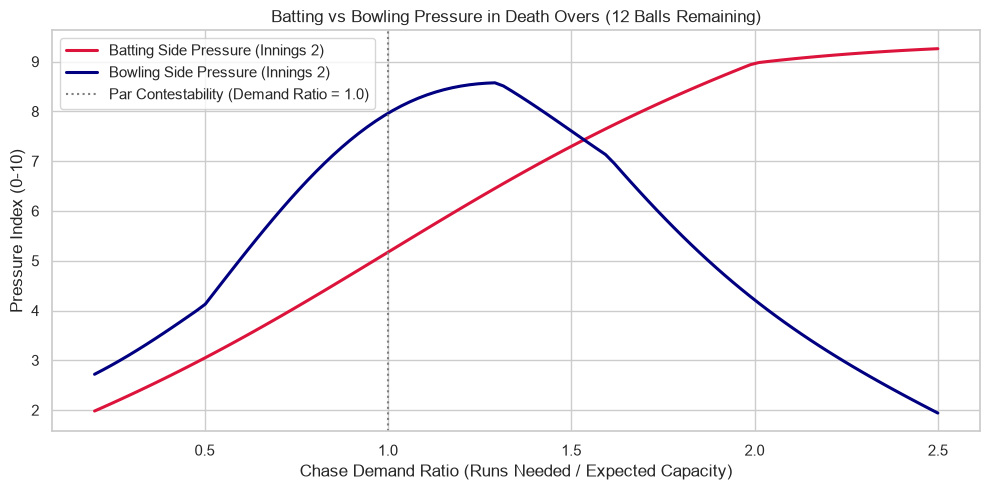

In [8]:
# Verify bowling pressure behavior across demand spectrum
demand_ratios = np.linspace(0.2, 2.5, 100)
b_rem_val = 12 # Final 2 overs
wkt_val = 6

e_cap = 20.0
runs_req_sim = demand_ratios * e_cap
rrr_sim = (runs_req_sim / b_rem_val) * 6.0

p_bat_sim = calculate_chasing_pressure(runs_req_sim, np.full_like(demand_ratios, b_rem_val), np.full_like(demand_ratios, wkt_val), rrr_sim, np.full_like(demand_ratios, e_cap))
p_bowl_sim = calculate_bowling_pressure(
    np.full_like(demand_ratios, 2), runs_req_sim, np.full_like(demand_ratios, b_rem_val),
    np.full_like(demand_ratios, wkt_val), rrr_sim, np.full_like(demand_ratios, e_cap),
    np.zeros_like(demand_ratios), np.full(len(demand_ratios), "Death"), p_bat_sim
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(demand_ratios, p_bat_sim, label="Batting Side Pressure (Innings 2)", color="crimson", linewidth=2.2)
ax.plot(demand_ratios, p_bowl_sim, label="Bowling Side Pressure (Innings 2)", color="navy", linewidth=2.2)
ax.axvline(1.0, color="gray", linestyle=":", label="Par Contestability (Demand Ratio = 1.0)")
ax.set_xlabel("Chase Demand Ratio (Runs Needed / Expected Capacity)")
ax.set_ylabel("Pressure Index (0-10)")
ax.set_title("Batting vs Bowling Pressure in Death Overs (12 Balls Remaining)")
ax.legend()
plt.tight_layout()
plt.show()


## 9. Super Over Pressure Treatment (Innings 3 & 4)

Super Overs feature completely different physical resource limits than standard 20-over matches:
* Maximum 6 legal balls.
* Maximum 2 wickets (a 2nd wicket terminates the innings immediately).
* In our dataset, exactly 6 matches featured Super Overs (38 deliveries total).

Because sample size is small (38 balls), fitting a standalone regression would be prone to overfitting. However, the physical rules of cricket dictate that every ball in a Super Over is inherently a High to Extreme pressure situation ($PI \in [7.5, 10.0]$).

We model Super Over pressure explicitly:
* **Innings 3 (1st Super Over):** $PI = 7.5 + 1.5 \cdot (\text{wickets}/2) + 1.0 \cdot ((6 - B)/6)$
* **Innings 4 (Super Over Chase):** $PI = 7.5 + 2.5 \cdot \text{clip}(\text{runs\_needed} / (B \cdot 2.5), 0, 1)$


In [9]:
# Inspect all 38 Super Over deliveries from the dataset
so_delivs = df_state[df_state["innings"] >= 3].copy()
p_so = calculate_super_over_pressure(
    so_delivs["innings"].values,
    so_delivs["cumulative_wickets_before"].values,
    so_delivs["balls_remaining_before"].values,
    so_delivs["runs_needed_before"].fillna(0).values
)
so_delivs["calculated_pi"] = np.round(p_so, 2)

print(f"Total Super Over deliveries: {len(so_delivs)}")
print(f"Super Over Pressure Range: {so_delivs['calculated_pi'].min():.2f} to {so_delivs['calculated_pi'].max():.2f}")
print(f"Mean Super Over Pressure: {so_delivs['calculated_pi'].mean():.2f}")


Total Super Over deliveries: 38
Super Over Pressure Range: 7.50 to 9.50
Mean Super Over Pressure: 8.24


## 10. Applying the Complete Pressure Engine to All 200,999 Deliveries

Now we execute the master `calculate_delivery_pressure` pipeline on the complete 200,999 delivery dataset.

This enriches every delivery with:
* `expected_remaining_runs`: Historical baseline capacity.
* `projected_final_score`: Projected 1st innings total.
* `par_score_gap`: Difference against format par.
* `chase_demand_ratio`: Scoring demand relative to capacity.
* `batting_pressure_index`: Batting team pressure.
* `bowling_pressure_index`: Bowling team pressure.
* `pressure_index`: Primary role-aligned pressure score.
* `pressure_category`: Low, Medium, High, Extreme.


In [10]:
# Execute complete delivery pressure calculation
df_pressure = calculate_delivery_pressure(df_state, calibrated_params)

print(f"Pressure calculation complete. Dataset shape: {df_pressure.shape}")
print("Primary Pressure Index Distribution:")
display(df_pressure["pressure_index"].describe().round(2))


Pressure calculation complete. Dataset shape: (200999, 68)
Primary Pressure Index Distribution:
count    200999.00
mean          4.75
std           2.25
min           0.00
25%           3.31
50%           4.42
75%           6.02
max          10.00


## 11. Pressure Distribution and Category Exploration

To understand the global properties of our Pressure Index, we examine how pressure is distributed across categories, match phases, and innings.

Our categorical thresholds are grounded in domain reasoning and distribution quantiles:
* **Low Pressure ([0.0, 3.5)):** Comfortable situations; batting team has plenty of wickets in hand and run rate well within capacity.
* **Medium Pressure ([3.5, 6.0)):** Competitive baseline; matches are in active balance.
* **High Pressure ([6.0, 8.0)):** Elevated demands; steep RRR, collapse recovery, or death-overs acceleration.
* **Extreme Pressure ([8.0, 10.0]):** Match-deciding situations; final-over chases, severe collapses, and Super Overs.


<string>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

<string>:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


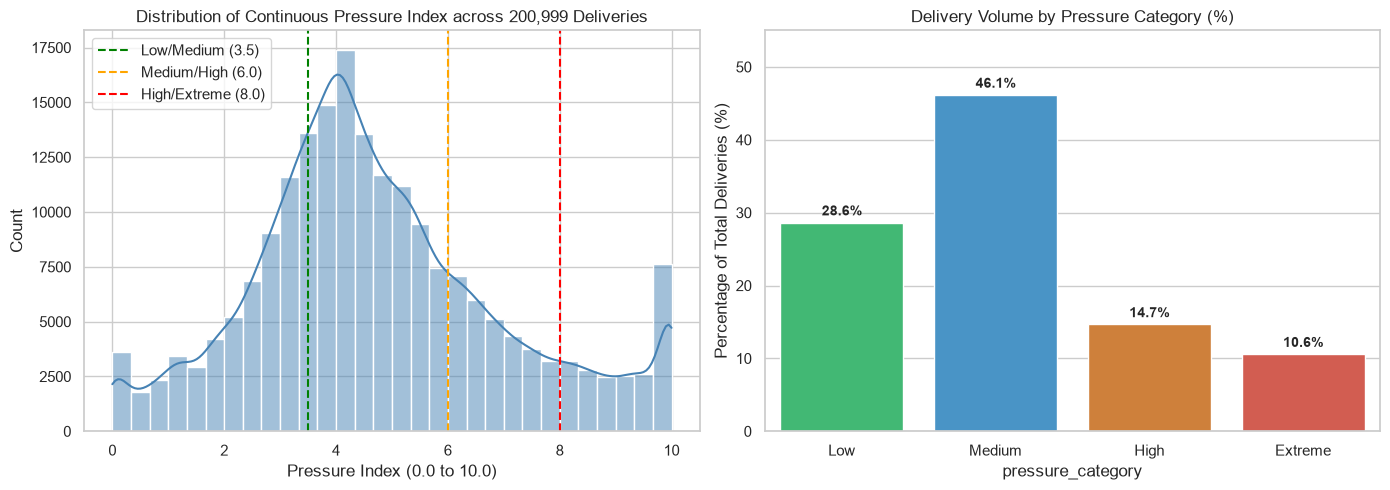

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Overall Pressure Histogram
sns.histplot(df_pressure["pressure_index"], bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].axvline(3.5, color="green", linestyle="--", label="Low/Medium (3.5)")
axes[0].axvline(6.0, color="orange", linestyle="--", label="Medium/High (6.0)")
axes[0].axvline(8.0, color="red", linestyle="--", label="High/Extreme (8.0)")
axes[0].set_title("Distribution of Continuous Pressure Index across 200,999 Deliveries")
axes[0].set_xlabel("Pressure Index (0.0 to 10.0)")
axes[0].legend()

# Plot 2: Pressure Category Percentages
cat_counts = df_pressure["pressure_category"].value_counts(normalize=True)[["Low", "Medium", "High", "Extreme"]] * 100
sns.barplot(x=cat_counts.index, y=cat_counts.values, ax=axes[1], palette=["#2ecc71", "#3498db", "#e67e22", "#e74c3c"])
axes[1].set_title("Delivery Volume by Pressure Category (%)")
axes[1].set_ylabel("Percentage of Total Deliveries (%)")
for i, v in enumerate(cat_counts.values):
    axes[1].text(i, v + 1.0, f"{v:.1f}%", ha="center", fontweight="bold")
axes[1].set_ylim(0, 55)

plt.tight_layout()
plt.show()


## 12. Iconic Match Case Studies: Verifying Real-World Scenarios

To confirm that our mathematical model reflects physical match reality, we inspect delivery-level pressure trajectories in two famous IPL matches:
1. **Case Study 1: The IPL 2023 Final (Chennai Super Kings vs Gujarat Titans, Match 21586).**
   CSK needed 171 in 15 overs (DLS revised). Tracing the final over reveals how Mohit Sharma and Ravindra Jadeja traded pressure.
2. **Case Study 2: Royal Challengers Bengaluru vs Sunrisers Hyderabad (Match 14129).**
   RCB collapsed to 68 all out. We verify how early wickets triggered extreme first-innings collapse pressure.


In [12]:
# Case Study 1: CSK vs GT Final Over
print("=== Case Study 1: CSK vs GT (Match 21586) Final Over ===")
csk_final = df_pressure[(df_pressure["match_id"] == 21586) & (df_pressure["innings"] == 2)].tail(6)
cols_csk = [
    "over_ball_num", "striker_name", "bowler_name", "cumulative_runs_before",
    "wickets_in_hand_before", "balls_remaining_before", "runs_needed_before",
    "required_run_rate_before", "pressure_index", "bowling_pressure_index", "pressure_category"
]
display(csk_final[cols_csk])

# Case Study 2: RCB Collapse vs SRH
print("\n=== Case Study 2: RCB Collapse (Match 14129) Powerplay Progression ===")
rcb_pp = df_pressure[(df_pressure["match_id"] == 14129) & (df_pressure["innings"] == 1)].head(18)
cols_rcb = [
    "overid", "over_ball_num", "striker_name", "cumulative_runs_before",
    "cumulative_wickets_before", "projected_final_score", "par_score_gap",
    "pressure_index", "pressure_category"
]
display(rcb_pp.iloc[[0, 3, 6, 11, 17]][cols_rcb])


=== Case Study 1: CSK vs GT (Match 21586) Final Over ===
       over_ball_num     striker_name   bowler_name  cumulative_runs_before  wickets_in_hand_before  balls_remaining_before  runs_needed_before  required_run_rate_before  pressure_index  bowling_pressure_index pressure_category
66954              1      Shivam Dube  Mohit Sharma                     158                       5                       6                13.0                      13.0            5.68                    9.01            Medium
66955              2      Shivam Dube  Mohit Sharma                     158                       5                       5                13.0                      15.6            6.49                    9.24              High
66956              3  Ravindra Jadeja  Mohit Sharma                     159                       5                       4                12.0                      18.0            7.16                    8.58              High
66957              4      Shiva

## 13. Executing the 10-Point Module 3 Validation Framework

Under our project engineering principles, no analytical model is accepted without programmatic verification. We execute a comprehensive 10-point test suite in `src/data_validator.py` covering:
1. Row count integrity (exactly 200,999 rows).
2. Key uniqueness on `(match_id, innings, overid, over_ball_num)`.
3. Range boundaries: all continuous scores strictly in $[0.0, 10.0]$.
4. Zero missing values across all pressure columns.
5. Monotonicity: higher RRR increases chase pressure.
6. Resource sanity: more wickets in hand reduces batting pressure.
7. First-innings collapse sensitivity: collapse state produces significantly higher pressure than stable powerplay.
8. Physical boundary sanity: post-target deliveries have pressure strictly 0.0.
9. Super Over segregation: all deliveries bounded within $[7.5, 10.0]$.
10. Outcome leakage check: pre-delivery pressure has near-zero correlation with current-ball runs.


In [13]:
# Run automated validation suite
validation_results = validate_pressure_model(df_pressure)

print("=== Module 3 Validation Suite Results ===")
all_passed = True
for check_id, res in validation_results.items():
    status = "PASSED [OK]" if res["passed"] else "FAILED [X]"
    print(f"  {status} | {check_id}: {res['description']}")
    print(f"           Details: {res['details']}")
    if not res["passed"]:
        all_passed = False

if all_passed:
    print("\nALL 10 MODULE 3 VALIDATION CHECKS PASSED WITH 100% SUCCESS!")
else:
    print("\nWARNING: Some validation checks failed. Please inspect.")


=== Module 3 Validation Suite Results ===
  PASSED [OK] | check_15_pressure_row_count: Row count matches Module 2 baseline (exactly 200,999 rows)
           Details: Observed: 200,999 rows
  PASSED [OK] | check_16_key_uniqueness: Delivery keys remain 100% unique after pressure enrichment
           Details: Zero duplicate deliveries
  PASSED [OK] | check_17_range_bounds: All continuous pressure scores are strictly bounded within [0.0, 10.0]
           Details: 0 records out of bounds
  PASSED [OK] | check_18_no_missing_pressure: Zero missing (NaN) values in pressure index columns
           Details: 0 missing values detected
  PASSED [OK] | check_19_chase_monotonicity: Higher required run rate monotonically increases chasing pressure
           Details: Correlation: 0.985
  PASSED [OK] | check_20_wicket_impact: More wickets in hand reduces batting pressure in identical ball/run situations
           Details: Correlation: -0.908
  PASSED [OK] | check_21_collapse_sensitivity: First-innin

## 14. Exporting Processed Assets, Limitations, and Next Steps

With all validation checks passed, the enriched delivery dataset is exported to `data/processed/` in both Parquet and CSV formats. Parquet provides columnar compression for rapid querying in downstream modules.

### Methodological Limitations:
1. **Venue and Pitch Normalization:** While our baseline model is format-aware (T20 vs T20I), venue-specific par variations (e.g., Wankhede vs Chepauk) are not yet explicitly isolated.
2. **Individual Batter/Bowler Quality:** The Pressure Index models situational difficulty independently of who is batting or bowling. Adjusting for batter matchup skill is intentionally reserved for player evaluation in Module 4.
3. **Super Over Sample Size:** With only 38 deliveries across 6 matches, Super Over ratings rely on physical resource limits ($B_{\text{max}}=6, W_{\text{max}}=2$) rather than dense statistical regression.

### Transition to Module 4:
In **Module 4: Player Performance Under Pressure**, we will use this delivery-level Pressure Index to evaluate batter and bowler reliability. We will measure how players perform across Low, Medium, High, and Extreme pressure situations, calculating Pressure-Weighted Strike Rates, Dot Ball Percentages, Wicket Survival, and Economy Rates to identify clutch match-winners for Rajasthan Royals' IPL 2027 auction strategy.


In [14]:
# Verify export file sizes and confirm pipeline completion
parquet_path = "../data/processed/ball_by_ball_pressure.parquet" if os.path.exists("../data/processed") else "data/processed/ball_by_ball_pressure.parquet"
csv_path = "../data/processed/ball_by_ball_pressure.csv" if os.path.exists("../data/processed") else "data/processed/ball_by_ball_pressure.csv"

if os.path.exists(parquet_path):
    print(f"Verified Parquet: {parquet_path} ({os.path.getsize(parquet_path) / (1024*1024):.2f} MB)")
if os.path.exists(csv_path):
    print(f"Verified CSV: {csv_path} ({os.path.getsize(csv_path) / (1024*1024):.2f} MB)")

print(f"Total Rows: {len(df_pressure):,} | Columns: {len(df_pressure.columns)}")
print("Module 3 implementation successfully completed.")


Verified Parquet: data/processed/ball_by_ball_pressure.parquet (7.73 MB)
Verified CSV: data/processed/ball_by_ball_pressure.csv (70.58 MB)
Total Rows: 200,999 | Columns: 68
Module 3 implementation successfully completed.
